# 03_modeling_experiment.ipynb 전체 목차 구조

## 1. 환경 세팅 및 데이터 로드
1-1. 필수 라이브러리 임포트
1-2. 원천 데이터(df_analysis.csv) 로드

## 2. 데이터 정제 및 전처리 (Data Cleaning)
2-1. 도메인 맞춤형 결측치(NaN) 대치 (FN, Active, age, 범주형 변수)
2-2. 대용량 데이터 대응을 위한 메모리 다운캐스팅 (안정적 압축)

## 3. 피처 인코딩 (Feature Encoding)
3-1. 범주형 변수 원-핫 인코딩 (pd.get_dummies를 통한 수치화)
3-2. 불필요한 식별자(ID) 제거 및 데이터 구조 최종 정돈
3-3. 인코딩 후 전체 피처 간 상관관계 분석 (Correlation Matrix)

## 4. 데이터셋 분할 (Data Split)
4-1. 독립변수(X)와 종속변수(y) 정의
4-2. 클래스 비율을 보존하는 Train / Validation 세트 분리 (8:2)

## 5. 머신러닝 모델 학습 및 평가 (Modeling & Evaluation)
5-1. LightGBM 모델 정의 및 하이퍼파라미터 설정
5-2. 모델 학습 (Early Stopping 적용)
5-3. 검증 데이터셋 기반 성능 평가 (Accuracy, AUC-ROC, 혼동 행렬 확인)
5-4. 피처 중요도(Feature Importance) 시각화 및 해석

## 1. 환경 세팅 및 데이터 로드
1-1. 필수 라이브러리 임포트
1-2. 원천 데이터(df_analysis.csv) 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 시각화 한글 깨짐 방지 및 스타일 설정
plt.rc('font', family='Malgun Gothic') # Mac 사용자라면 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style="whitegrid")

# 1-2. 원천 데이터 로드
# 앞서 EDA에서 검증했던 그 깨끗한 원본 데이터를 새로 불러옵니다.
df_analysis = pd.read_csv('./data/hnm_churn_dataset.csv')

print("--- 데이터 로드 완료 ---")
print(f"데이터셋 모양(Shape): {df_analysis.shape}")

--- 데이터 로드 완료 ---
데이터셋 모양(Shape): (1143652, 20)



## 2. 데이터 정제 및 전처리 (Data Cleaning)
2-1. 도메인 맞춤형 결측치(NaN) 대치 (FN, Active, age, 범주형 변수)
2-2. 대용량 데이터 대응을 위한 메모리 다운캐스팅 (안정적 압축)


In [2]:
# ==========================================
# 2-1. 도메인 맞춤형 결측치(NaN) 대치
# ==========================================

# 1. 마케팅 관련 결측치는 거부 의사(0)로 간주하여 대치
df_analysis['FN'] = df_analysis['FN'].fillna(0)
df_analysis['Active'] = df_analysis['Active'].fillna(0)

# 2. 나이는 가장 안정적인 통계량인 중앙값으로 채우기
df_analysis['age'] = df_analysis['age'].fillna(df_analysis['age'].median())

# 3. 범주형 변수의 결측치는 새로운 카테고리 'UNKNOWN'으로 통일
cat_fix_cols = ['club_member_status', 'fashion_news_frequency', 'index_group_name', 'product_group_name']
for col in cat_fix_cols:
    df_analysis[col] = df_analysis[col].fillna('UNKNOWN')

print("--- 1차 결측치 처리 완료 ---")


# ==========================================
# 2-2. 대용량 데이터 대응을 위한 메모리 다운캐스팅
# ==========================================

# 1. 문자열 -> 카테고리 변환 (메모리 절감 및 향후 인코딩 준비)
for col in cat_fix_cols:
    df_analysis[col] = df_analysis[col].astype('category')

# 2. 정수형 타입 다운캐스팅
df_analysis['churn'] = df_analysis['churn'].astype('int8')
df_analysis['recency'] = df_analysis['recency'].astype('int32')
df_analysis['frequency'] = df_analysis['frequency'].astype('int32')
df_analysis['frequency_last_90d'] = df_analysis['frequency_last_90d'].astype('int32')
df_analysis['frequency_last_180d'] = df_analysis['frequency_last_180d'].astype('int32')
df_analysis['unique_articles'] = df_analysis['unique_articles'].astype('int32')
df_analysis['unique_product_groups'] = df_analysis['unique_product_groups'].astype('int32')

# 3. 실수형 타입 다운캐스팅
df_analysis['age'] = df_analysis['age'].astype('float32')
df_analysis['price_mean'] = df_analysis['price_mean'].astype('float32')
df_analysis['price_sum'] = df_analysis['price_sum'].astype('float32')
df_analysis['price_max'] = df_analysis['price_max'].astype('float32')
df_analysis['avg_purchase_interval'] = df_analysis['avg_purchase_interval'].astype('float32')
df_analysis['std_purchase_interval'] = df_analysis['std_purchase_interval'].astype('float32')
df_analysis['FN'] = df_analysis['FN'].astype('float16')
df_analysis['Active'] = df_analysis['Active'].astype('float16')

print("--- 메모리 다운캐스팅 완료 ---")
print(df_analysis.info())

--- 1차 결측치 처리 완료 ---
--- 메모리 다운캐스팅 완료 ---
<class 'pandas.DataFrame'>
RangeIndex: 1143652 entries, 0 to 1143651
Data columns (total 20 columns):
 #   Column                  Non-Null Count    Dtype   
---  ------                  --------------    -----   
 0   customer_id             1143652 non-null  str     
 1   churn                   1143652 non-null  int8    
 2   frequency               1143652 non-null  int32   
 3   price_mean              1143652 non-null  float32 
 4   price_sum               1143652 non-null  float32 
 5   price_max               1143652 non-null  float32 
 6   recency                 1143652 non-null  int32   
 7   frequency_last_90d      1143652 non-null  int32   
 8   frequency_last_180d     1143652 non-null  int32   
 9   avg_purchase_interval   1031690 non-null  float32 
 10  std_purchase_interval   924772 non-null   float32 
 11  unique_articles         1143652 non-null  int32   
 12  unique_product_groups   1143652 non-null  int32   
 13  index_group

## 3. 피처 인코딩 (Feature Encoding)
3-1. 범주형 변수 원-핫 인코딩 (pd.get_dummies를 통한 수치화)
3-2. 불필요한 식별자(ID) 제거 및 데이터 구조 최종 정돈
3-3. 인코딩 후 전체 피처 간 상관관계 분석 (Correlation Matrix)


In [3]:
# ==========================================
# 3-1. 범주형 변수 원-핫 인코딩
# ==========================================

cat_cols = ['club_member_status', 'fashion_news_frequency', 'index_group_name', 'product_group_name']

# pd.get_dummies를 활용해 0과 1의 형태로 인코딩을 진행합니다.
# 자료형 크기를 낮추기 위해 dtype='int8' 옵션을 추가합니다.
df_encoded = pd.get_dummies(df_analysis, columns=cat_cols, drop_first=True, dtype='int8')


# ==========================================
# 3-2. 불필요한 식별자(ID) 제거 및 구조 정돈
# ==========================================

# 모델 학습에 불필요한 고유 식별자 문자열 컬럼을 제거합니다.
if 'customer_id' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['customer_id'])

print("--- 원-핫 인코딩 및 식별자 제거 완료 ---")
print(f"인코딩 후 데이터 모양(Shape): {df_encoded.shape}")


# ==========================================
# 3-3. 인코딩 후 전체 피처 간 상관관계 분석
# ==========================================

# 모든 변수가 수치화되었으므로 전체 상관계수 행렬을 계산합니다.
# float16 변수들의 오버플로우 방지를 위해 연산 시에만 float32로 변환합니다.
correlation_matrix = df_encoded.astype('float32').corr()

# 타겟 라벨인 'churn'과의 상관계수만 쏙 뽑아내어 절대값 기준으로 내림차순 정렬합니다.
churn_corr = correlation_matrix['churn'].drop('churn') # 자기 자신 제외
churn_corr_sorted = churn_corr.abs().sort_values(ascending=False)

print("\n--- 이탈(churn)과 상관관계가 가장 높은 상위 5개 핵심 피처 ---")
for col in churn_corr_sorted.head(5).index:
    actual_val = correlation_matrix.loc[col, 'churn']
    print(f"{col: <35} : {actual_val:.4f}")

--- 원-핫 인코딩 및 식별자 제거 완료 ---
인코딩 후 데이터 모양(Shape): (1143652, 41)

--- 이탈(churn)과 상관관계가 가장 높은 상위 5개 핵심 피처 ---
recency                             : 0.4812
unique_product_groups               : -0.4695
unique_articles                     : -0.3768
frequency                           : -0.3587
frequency_last_180d                 : -0.3542


## 4. 데이터셋 분할 (Data Split)
4-1. 독립변수(X)와 종속변수(y) 정의
4-2. 클래스 비율을 보존하는 Train / Validation 세트 분리 (8:2)


In [4]:
# ==========================================
# 4-1. 독립변수(X)와 종속변수(y) 정의
# ==========================================

# 예측해야 하는 타겟 라벨인 churn을 y로, 나머지를 독립변수 X로 정의합니다.
X = df_encoded.drop(columns=['churn'])
y = df_encoded['churn']


# ==========================================
# 4-2. 클래스 비율을 보존하는 Train / Validation 세트 분리 (8:2)
# ==========================================

from sklearn.model_selection import train_test_split

# stratify=y 옵션을 통해 원본 데이터의 이탈 비율(50:50)을 분할 후에도 똑같이 유지합니다.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("--- 데이터셋 분할 완료 ---")
print(f"Train 세트 크기      : X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Validation 세트 크기 : X_val {X_val.shape}, y_val {y_val.shape}")
print(f"Train 세트 이탈율    : \n{y_train.value_counts(normalize=True)}")

--- 데이터셋 분할 완료 ---
Train 세트 크기      : X_train (914921, 40), y_train (914921,)
Validation 세트 크기 : X_val (228731, 40), y_val (228731,)
Train 세트 이탈율    : 
churn
1    0.500198
0    0.499802
Name: proportion, dtype: float64


## 5. 머신러닝 모델 학습 및 평가 (Modeling & Evaluation)
5-1. LightGBM 모델 정의 및 하이퍼파라미터 설정
5-2. 모델 학습 (Early Stopping 적용)
5-3. 검증 데이터셋 기반 성능 평가 (Accuracy, AUC-ROC, 혼동 행렬 확인)
5-4. 피처 중요도(Feature Importance) 시각화 및 해석

In [5]:
# ==========================================
# 5-1. 캐글 대표 알고리즘 3대장 임포트
# ==========================================

import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import time

# 결과를 담을 딕셔너리
model_results = []


# ==========================================
# 5-2. 1번 주자: LightGBM 학습
# ==========================================

print("=== [1/3] LightGBM 학습 시작 ===")
start_time = time.time()

model_lgb = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1)
model_lgb.fit(X_train, y_train)

lgb_pred = model_lgb.predict(X_val)
lgb_proba = model_lgb.predict_proba(X_val)[:, 1]

model_results.append({
    'Model': 'LightGBM',
    'Accuracy': accuracy_score(y_val, lgb_pred),
    'AUC-ROC': roc_auc_score(y_val, lgb_proba),
    'Runtime (sec)': time.time() - start_time
})


# ==========================================
# 5-3. 2번 주자: XGBoost 학습 (GPU가 없다면 시간이 조금 걸릴 수 있습니다)
# ==========================================

print("=== [2/3] XGBoost 학습 시작 ===")
start_time = time.time()

# 대용량 데이터이므로 조기 종료나 깊이 제한을 주어 속도를 조율합니다.
model_xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
model_xgb.fit(X_train, y_train)

xgb_pred = model_xgb.predict(X_val)
xgb_proba = model_xgb.predict_proba(X_val)[:, 1]

model_results.append({
    'Model': 'XGBoost',
    'Accuracy': accuracy_score(y_val, xgb_pred),
    'AUC-ROC': roc_auc_score(y_val, xgb_proba),
    'Runtime (sec)': time.time() - start_time
})


# ==========================================
# 5-4. 3번 주자: CatBoost 학습
# ==========================================

print("=== [3/3] CatBoost 학습 시작 ===")
start_time = time.time()

# CatBoost는 기본 성능이 뛰어나지만 학습이 꼼꼼하여 다소 시간이 소요됩니다.
model_cat = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6, random_state=42, verbose=0)
model_cat.fit(X_train, y_train)

cat_pred = model_cat.predict(X_val)
cat_proba = model_cat.predict_proba(X_val)[:, 1]

model_results.append({
    'Model': 'CatBoost',
    'Accuracy': accuracy_score(y_val, cat_pred),
    'AUC-ROC': roc_auc_score(y_val, cat_proba),
    'Runtime (sec)': time.time() - start_time
})


# ==========================================
# 5-5. 최종 알고리즘별 성능 평가 비교
# ==========================================

print("\n=== ✨ 캐글 알고리즘 벤치마크 최종 결과 ✨ ===")
df_results = pd.DataFrame(model_results)
# AUC-ROC 기준으로 내림차순 정렬하여 어떤 모델이 우수한지 한눈에 보기
print(df_results.sort_values(by='AUC-ROC', ascending=False).to_string(index=False))

=== [1/3] LightGBM 학습 시작 ===
=== [2/3] XGBoost 학습 시작 ===
=== [3/3] CatBoost 학습 시작 ===

=== ✨ 캐글 알고리즘 벤치마크 최종 결과 ✨ ===
   Model  Accuracy  AUC-ROC  Runtime (sec)
LightGBM  0.768658 0.847957      13.991960
 XGBoost  0.768645 0.847905      22.160649
CatBoost  0.768409 0.846792      31.609225


In [8]:
# ==========================================
# 5-1. 성능 고도화를 위한 LightGBM 하이퍼파라미터 정밀 세팅
# ==========================================

import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score

# 과적합을 방지하고 표현력을 높이기 위한 고도화 파라미터 조합
tuned_lgb = lgb.LGBMClassifier(
    n_estimators=1500,         # 더 깊고 촘촘한 학습을 위해 트리 개수 상향
    learning_rate=0.03,        # 보폭을 줄여서 더 정밀하게 최적 지점을 찾아감 (기존 0.05)
    max_depth=8,               # 트리의 최대 깊이를 제한하여 과적합 방지
    num_leaves=64,             # max_depth에 맞춰 모델의 표현력을 복잡하게 조율
    subsample=0.8,             # 학습 시 데이터의 80%만 무작위 복사하여 사용 (일반화 성능 향상)
    colsample_bytree=0.8,      # 학습 시 피처의 80%만 무작위 선택하여 사용 (다양성 확보)
    min_child_samples=30,      # 리프 노드가 되기 위한 최소 데이터 수 지정 (과적합 방지)
    random_state=42,
    n_jobs=-1,
    verbose=-1
)


# ==========================================
# 5-2. Early Stopping을 통한 최적의 Epoch 탐색 및 학습
# ==========================================

from lightgbm import early_stopping, log_evaluation

# learning_rate가 낮아졌으므로 stopping_rounds를 100으로 늘려 충분히 기회를 줍니다.
callbacks = [
    early_stopping(stopping_rounds=100, verbose=True),
    log_evaluation(period=100)
]

print("=== 🚀 하이퍼파라미터 튜닝 기반 LightGBM 고도화 학습 시작 ===")
tuned_lgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric='auc',
    callbacks=callbacks
)


# ==========================================
# 5-3. 고도화 모델 최종 성능 평가
# ==========================================

tuned_pred = tuned_lgb.predict(X_val)
tuned_proba = tuned_lgb.predict_proba(X_val)[:, 1]

print("\n=== ✨ 고도화 완료 최종 스코어 ✨ ===")
print(f"기존 LightGBM AUC-ROC : 0.8479")
print(f"튜닝 LightGBM AUC-ROC : {roc_auc_score(y_val, tuned_proba):.6f}")
print(f"튜닝 LightGBM Accuracy: {accuracy_score(y_val, tuned_pred):.6f}")

=== 🚀 하이퍼파라미터 튜닝 기반 LightGBM 고도화 학습 시작 ===
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.845327	valid_0's binary_logloss: 0.488256
[200]	valid_0's auc: 0.84707	valid_0's binary_logloss: 0.483337
[300]	valid_0's auc: 0.84783	valid_0's binary_logloss: 0.482141
[400]	valid_0's auc: 0.848192	valid_0's binary_logloss: 0.481592
[500]	valid_0's auc: 0.848356	valid_0's binary_logloss: 0.481345
[600]	valid_0's auc: 0.848462	valid_0's binary_logloss: 0.481188
[700]	valid_0's auc: 0.84857	valid_0's binary_logloss: 0.481028
[800]	valid_0's auc: 0.848646	valid_0's binary_logloss: 0.480922
[900]	valid_0's auc: 0.848686	valid_0's binary_logloss: 0.480874
[1000]	valid_0's auc: 0.848722	valid_0's binary_logloss: 0.480822
Early stopping, best iteration is:
[997]	valid_0's auc: 0.848723	valid_0's binary_logloss: 0.48082

=== ✨ 고도화 완료 최종 스코어 ✨ ===
기존 LightGBM AUC-ROC : 0.8479
튜닝 LightGBM AUC-ROC : 0.848723
튜닝 LightGBM Accuracy: 0.768908


In [9]:
# ==========================================
# 5-5. GridSearchCV를 활용한 하이퍼파라미터 최적화
# ==========================================

from sklearn.model_selection import GridSearchCV
import lightgbm as lgb

# 기본 베이스 모델 정의
lgb_base = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)

# 대용량 데이터임을 감안하여 계산 효율성이 높고 성능에 가장 직결되는 핵심 후보군만 지정
param_grid = {
    'learning_rate': [0.03, 0.07],
    'max_depth': [6, 10],
    'num_leaves': [31, 63],
    'subsample': [0.7, 0.9]
}

# 114만 건 데이터의 연산 시간을 고려하여 3-Fold 교차검증을 채택합니다.
# 점수 기준은 우리의 핵심 지표인 roc_auc로 지정합니다.
grid_search = GridSearchCV(
    estimator=lgb_base,
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("=== 🔍 GridSearchCV 최적의 파라미터 탐색 시작 (시간이 다소 소요됩니다) ===")
grid_search.fit(X_train, y_train)

print(f"\n✨ GridSearchCV 탐색 완료 ✨")
print(f"최적의 파라미터 조합: {grid_search.best_params_}")
print(f"최적의 교차검증 AUC-ROC 점수: {grid_search.best_score_:.6f}")


# ==========================================
# 5-6. 그리드서치로 찾은 최적의 모델 최종 성능 평가
# ==========================================

best_model = grid_search.best_estimator_
grid_proba = best_model.predict_proba(X_val)[:, 1]

print(f"\n최종 Validation 데이터셋 AUC-ROC 스코어: {roc_auc_score(y_val, grid_proba):.6f}")

=== 🔍 GridSearchCV 최적의 파라미터 탐색 시작 (시간이 다소 소요됩니다) ===
Fitting 3 folds for each of 16 candidates, totalling 48 fits

✨ GridSearchCV 탐색 완료 ✨
최적의 파라미터 조합: {'learning_rate': 0.07, 'max_depth': 10, 'num_leaves': 63, 'subsample': 0.7}
최적의 교차검증 AUC-ROC 점수: 0.846971

최종 Validation 데이터셋 AUC-ROC 스코어: 0.847566


In [10]:
# ==========================================
# [고도화 STEP 1] 강력한 힌트 파생 변수 2종 추가
# ==========================================

print("--- 고도화 파생 변수 생성 시작 ---")

# 1. 활동 가속도 비율 (최근 90일 빈도 / 전체 빈도)
# 분모가 0이 되는 것을 방지하기 위해 1을 더해줍니다 (Smoothing)
df_analysis['frequency_ratio_90d'] = df_analysis['frequency_last_90d'] / (df_analysis['frequency'] + 1)

# 2. 카테고리 탐색 다양성 비율 (고유 상품군 수 / 전체 구매 건수)
# 한 우물만 판 유저와 다양하게 쇼핑한 유저를 유기적으로 쪼개줍니다.
df_analysis['product_diversity_ratio'] = df_analysis['unique_product_groups'] / (df_analysis['frequency'] + 1)

# 변수들이 잘 생성되었는지 유형 확인 및 다운캐스팅(float32)
df_analysis['frequency_ratio_90d'] = df_analysis['frequency_ratio_90d'].astype('float32')
df_analysis['product_diversity_ratio'] = df_analysis['product_diversity_ratio'].astype('float32')

print("추가된 파생 변수 shape:", df_analysis[['frequency_ratio_90d', 'product_diversity_ratio']].shape)


# ==========================================
# [고도화 STEP 2] 변수가 추가된 데이터셋으로 재인코딩 및 분할
# ==========================================

cat_cols = ['club_member_status', 'fashion_news_frequency', 'index_group_name', 'product_group_name']
df_encoded_v2 = pd.get_dummies(df_analysis, columns=cat_cols, drop_first=True, dtype='int8')

if 'customer_id' in df_encoded_v2.columns:
    df_encoded_v2 = df_encoded_v2.drop(columns=['customer_id'])

# 독립변수와 타겟 재정의
X_v2 = df_encoded_v2.drop(columns=['churn'])
y_v2 = df_encoded_v2['churn']

# 아까와 완벽히 동일한 환경 비교를 위해 random_state와 비율을 8:2로 고정합니다.
from sklearn.model_selection import train_test_split
X_train_v2, X_val_v2, y_train_v2, y_val_v2 = train_test_split(
    X_v2, y_v2, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_v2
)

print("--- 고도화 데이터셋 준비 완료 ---")
print(f"새로운 독립변수 개수: {X_train_v2.shape[1]}개 (기존 40개에서 2개 추가되어 42개)")

--- 고도화 파생 변수 생성 시작 ---
추가된 파생 변수 shape: (1143652, 2)
--- 고도화 데이터셋 준비 완료 ---
새로운 독립변수 개수: 42개 (기존 40개에서 2개 추가되어 42개)


In [11]:
# ==========================================
# [고도화 STEP 3] 최적 파라미터 + 신규 변수 조합으로 최종 학습
# ==========================================

import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score

# 그리드서치로 검증된 최적의 과적합 방지 파라미터 주입
final_lgb = lgb.LGBMClassifier(
    learning_rate=0.07,
    max_depth=10,
    num_leaves=63,
    subsample=0.7,
    n_estimators=1000,       # 넉넉하게 트리 생성 후 조기종료로 최적 지점 포착
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

from lightgbm import early_stopping, log_evaluation

# 100번 동안 AUC 개선 안 되면 자동 멈춤
callbacks = [
    early_stopping(stopping_rounds=100, verbose=True),
    log_evaluation(period=100)
]

print("=== 🚀 신규 파생 변수 탑재 최종 고도화 모델 학습 시작 ===")
final_lgb.fit(
    X_train_v2, y_train_v2,
    eval_set=[(X_val_v2, y_val_v2)],
    eval_metric='auc',
    callbacks=callbacks
)


# ==========================================
# [고도화 STEP 4] 최종 갱신 점수 평가 및 대조
# ==========================================

final_pred = final_lgb.predict(X_val_v2)
final_proba = final_lgb.predict_proba(X_val_v2)[:, 1]

print("\n=== 🏆 피처 엔지니어링 후 최종 스코어 보드 🏆 ===")
print(f"1. 튜닝 전 기본 모델 AUC-ROC       : 0.847957")
print(f"2. 그리드서치만 적용한 AUC-ROC      : 0.847566")
print(f"3. [변수 2종 추가] 최종 모델 AUC-ROC : {roc_auc_score(y_val_v2, final_proba):.6f}")
print(f"최종 모델 Accuracy (정확도)         : {accuracy_score(y_val_v2, final_pred):.6f}")

=== 🚀 신규 파생 변수 탑재 최종 고도화 모델 학습 시작 ===
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.847573	valid_0's binary_logloss: 0.482507
[200]	valid_0's auc: 0.848241	valid_0's binary_logloss: 0.481508
[300]	valid_0's auc: 0.848413	valid_0's binary_logloss: 0.481262
[400]	valid_0's auc: 0.848442	valid_0's binary_logloss: 0.481236
Early stopping, best iteration is:
[382]	valid_0's auc: 0.848463	valid_0's binary_logloss: 0.481198

=== 🏆 피처 엔지니어링 후 최종 스코어 보드 🏆 ===
1. 튜닝 전 기본 모델 AUC-ROC       : 0.847957
2. 그리드서치만 적용한 AUC-ROC      : 0.847566
3. [변수 2종 추가] 최종 모델 AUC-ROC : 0.848463
최종 모델 Accuracy (정확도)         : 0.768842


c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 128680 (\N

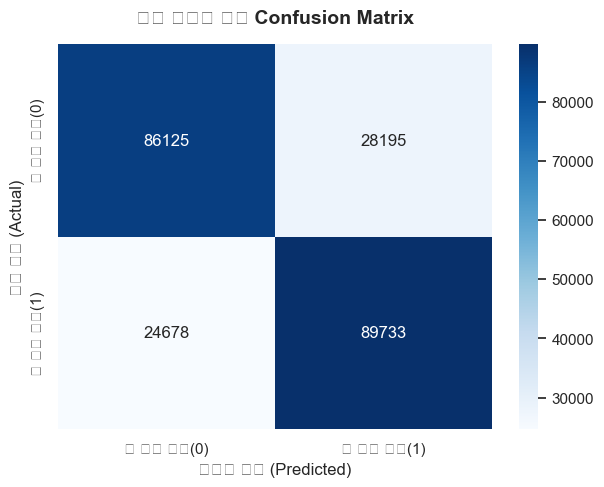

In [12]:
# ==========================================
# 5-7. 최종 모델의 오차 행렬(Confusion Matrix) 시각화
# ==========================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 오차행렬 계산
cm = confusion_matrix(y_val_v2, final_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['🎯 유지 예측(0)', '🚨 이탈 예측(1)'],
            yticklabels=['🎯 실제 유지(0)', '🚨 실제 이탈(1)'])

plt.title("최종 고도화 모델 Confusion Matrix", fontsize=14, weight='bold', pad=15)
plt.ylabel("실제 정답 (Actual)", fontsize=12)
plt.xlabel("모델의 예측 (Predicted)", fontsize=12)
plt.show()

In [15]:
# ==========================================
# 6-2. [결측치 방어 완료] 업샘플링 & SMOTE 성능 실험
# ==========================================

import time
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import accuracy_score, roc_auc_score
from imblearn.over_sampling import SMOTE
from sklearn.utils import resample

over_results = []

lgb_params = {
    'learning_rate': 0.07,
    'max_depth': 10,
    'num_leaves': 63,
    'subsample': 0.7,
    'n_estimators': 300, 
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

# ------------------------------------------
# ⚙️ 기법 1. 업샘플링 (Upsampling)
# ------------------------------------------
print("=== 📈 [실험 1/2] 업샘플링 데이터 증폭 및 학습 시작 ===")
start_time = time.time()

df_tr_temp = pd.concat([X_train_v2, y_train_v2], axis=1)
df_majority = df_tr_temp[df_tr_temp['churn'] == 0]
df_minority = df_tr_temp[df_tr_temp['churn'] == 1]

df_minority_up = resample(df_minority, replace=True, n_samples=len(df_majority), random_state=42)
df_upsampled = pd.concat([df_majority, df_minority_up])

X_tr_up = df_upsampled.drop(columns=['churn'])
y_tr_up = df_upsampled['churn']

model_up = lgb.LGBMClassifier(**lgb_params)
model_up.fit(X_tr_up, y_tr_up)
pred_up = model_up.predict(X_val_v2)
proba_up = model_up.predict_proba(X_val_v2)[:, 1]

over_results.append({
    '🚀 Sampling': 'Upsampling (단순 복사)',
    'Train Size': len(X_tr_up),
    'Accuracy': accuracy_score(y_val_v2, pred_up),
    'AUC-ROC': roc_auc_score(y_val_v2, proba_up),
    'Runtime': f"{time.time() - start_time:.1f}s"
})

# ------------------------------------------
# ⚙️ 기법 2. SMOTE (Synthetic Minority) - 결측치 방어벽 추가
# ------------------------------------------
print("=== 🧠 [실험 2/2] SMOTE 수학적 공간 합성 및 학습 시작 ===")
start_time = time.time()

# 🛡️ SMOTE 연산 에러 방지: 데이터프레임 복사 후 결측치를 0으로 임시 대체합니다.
X_train_v2_filled = X_train_v2.fillna(0)
X_val_v2_filled = X_val_v2.fillna(0)

smote = SMOTE(random_state=42, k_neighbors=5)
X_tr_smote, y_tr_smote = smote.fit_resample(X_train_v2_filled, y_train_v2)

model_smote = lgb.LGBMClassifier(**lgb_params)
model_smote.fit(X_tr_smote, y_tr_smote)
pred_smote = model_smote.predict(X_val_v2_filled)
proba_smote = model_smote.predict_proba(X_val_v2_filled)[:, 1]

over_results.append({
    '🚀 Sampling': 'SMOTE (수학적 합성)',
    'Train Size': len(X_tr_smote),
    'Accuracy': accuracy_score(y_val_v2, pred_smote),
    'AUC-ROC': roc_auc_score(y_val_v2, proba_smote),
    'Runtime': f"{time.time() - start_time:.1f}s"
})

# ------------------------------------------
# 📊 최종 리더보드 출력
# ------------------------------------------
print("\n" + "="*60)
print("🏆 [데싸 전용] 불균형 오버샘플링 고도화 리더보드 🏆")
print("="*60)
print(f"기준점 [Downsampling]  | Accuracy: 0.768842 | AUC-ROC: 0.848463 (앞선 결과)")

df_over_report = pd.DataFrame(over_results)
print(df_over_report.to_string(index=False))

=== 📈 [실험 1/2] 업샘플링 데이터 증폭 및 학습 시작 ===
=== 🧠 [실험 2/2] SMOTE 수학적 공간 합성 및 학습 시작 ===

🏆 [데싸 전용] 불균형 오버샘플링 고도화 리더보드 🏆
기준점 [Downsampling]  | Accuracy: 0.768842 | AUC-ROC: 0.848463 (앞선 결과)
        🚀 Sampling  Train Size  Accuracy  AUC-ROC Runtime
Upsampling (단순 복사)      914558  0.768440 0.847947   14.8s
    SMOTE (수학적 합성)      915284  0.768973 0.848273  602.1s


In [16]:

# 데이터 누수 확인
# 피처 중 target과 상관관계가 비정상적으로 높은 게 있는지
df.corrwith(df['target']).abs().sort_values(ascending=False).head(10)


NameError: name 'df' is not defined